In [55]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import linalg as sla
from scipy import sparse as sp
from rk4 import rk4solve
from part2 import H_number, H_drive, H_time

Linblads master equation
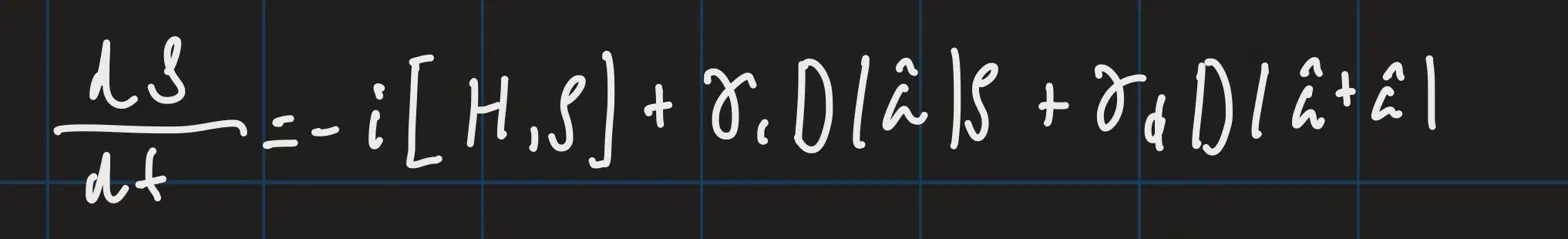

In [56]:
def Dissipation(t, rho, gamma):
    return gamma * t @ rho @ t.conj().T - 0.5 * gamma * (t.conj().T @ t @ rho + rho @ t.conj().T @ t)
def Lindblad(T, rho, H, gamma): 
    gamma1, gamma2 = gamma
    T1, T2 = T
    return -1j * (H @ rho - rho @ H) + Dissipation(T1, rho, gamma1) + Dissipation(T2, rho, gamma2)

In [66]:
E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz
E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
omega= E_c/3 # the amplitude of the drive must be smaller than E_c
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
c0=np.array([1,0,0]) # the initial condition
T1, T2= 100 * 1e3, 50 * 1e3 # the relaxation and dephasing times in ns
gamma=np.array([1/T1,2 * (1/T2 - 1 / (2*T1))]) # the dissipation rates for the two levels
T1 = np.array([[0,1,0],[0,0,np.sqrt(2)],[0,0,0]],dtype=complex) # the lowering operator a on 3 levels
T2 = np.diag([0,1,2]) # adagger a 
T = np.array([T1,T2]) # the array of the two operators
rho0 = np.array([[1,0,0],[0,0,0],[0,0,0]]) # the initial density matrix

H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = E[1]-E[0] # the energy gap between the ground state and the first excited state

A= U.T @ np.diag(N) @ U #the coupling term between the different states

In [67]:
def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equation
    H = H_time(t,H_0,A,omega,w)
    return Lindblad(T, rho, H, gamma)

In [68]:
t,C = rk4solve(f, rho0, 0, 0.005, 100)

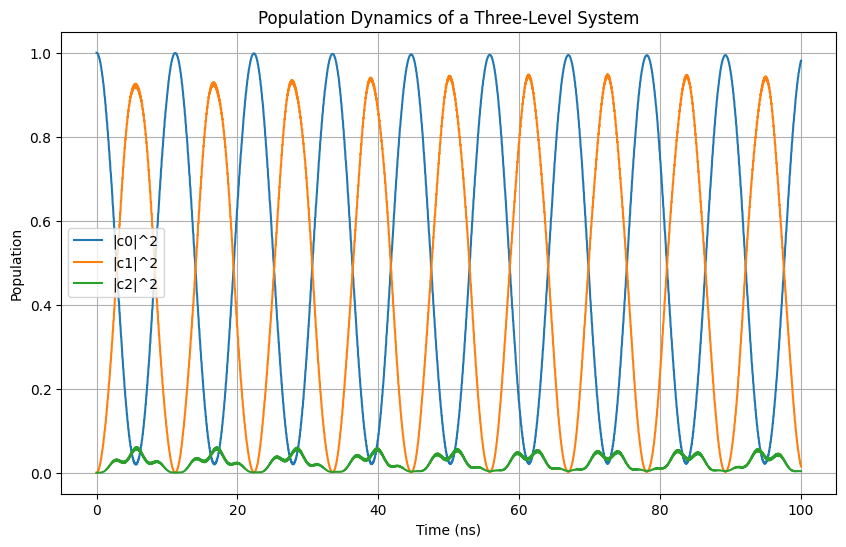

In [69]:
plt.figure(figsize=(10, 6))
plt.plot(t, C[:, 0, 0].real, label='|c0|^2')
plt.plot(t, C[:, 1, 1].real, label='|c1|^2')
plt.plot(t, C[:, 2, 2].real, label='|c2|^2')
plt.xlabel('Time (ns)')
plt.ylabel('Population')
plt.title('Population Dynamics of a Three-Level System')
plt.legend()
plt.grid()